# 라벨·내용물 별도 학습 / 3모델 성능 비교 / ONNX 저장 / 사진 테스트
MobileNetV3-Small, EfficientNet-B0, ResNet18을 라벨용·내용물용으로 각각 학습합니다(총 6개 후보).
ImageDataGenerator, 동결 ImageNet 전이학습, GAP→Dense128→Dropout 흐름을 사용합니다.
입력 사진에는 페트병 한 개가 충분히 크게 보여야 합니다. 사진 전체를 resize하며 검출·crop 과정은 없습니다.
각 작업에서 검증 macro F1로 후보를 선택하고 고정 테스트 성능을 별도로 보고합니다.
사진 테스트는 라벨 판별기→내용물 판별기 순서로 실행하며, 둘 다 없으면 선별 기준 통과입니다.



In [ ]:
import sys,subprocess
print('현재 Python:',sys.version)
python_version=sys.version_info[:2]
if not (3,10)<=python_version<=(3,13):
    raise RuntimeError(f'현재 Python은 {python_version}입니다. 이 TensorFlow 노트북은 Python 3.10~3.13 환경이 필요합니다. Colab의 호환 런타임을 사용하세요.')

# 최초 한 번 실행한 뒤 런타임을 재시작하고 다음 Drive 셀부터 실행하세요.
# Python 3.13에서는 기존 TensorFlow 2.16 / NumPy 1.26 고정을 사용하지 않습니다.
INSTALL=True
if INSTALL:
    if python_version==(3,13):
        packages=['tensorflow==2.20.0','tf2onnx==1.17.0','numpy>=2.1,<2.3',
                  'onnx>=1.17,<2','onnxruntime>=1.21,<2','torch==2.8.0','torchvision==0.23.0']
    else:
        packages=['tensorflow==2.16.2','numpy==1.26.4','tf2onnx==1.16.1',
                  'onnx==1.16.2','onnxruntime==1.20.1','torch==2.5.1','torchvision==0.20.1']
    packages+=['pandas','scikit-learn','matplotlib','pillow','scipy']
    subprocess.check_call([sys.executable,'-m','pip','install',*packages])
    print('설치 완료. 런타임을 재시작하고 다음 Drive 마운트 셀부터 실행하세요.')


현재 Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
설치 완료. 런타임을 재시작하고 다음 Drive 마운트 셀부터 실행하세요.


In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile
drive.mount('/content/drive')

ZIP_PATH=Path('/content/drive/MyDrive/ai/final/model_multilabel/dataset_multi.zip')  # 수정
RESULTS_ROOT=Path('/content/drive/MyDrive/ai/final/model_multilabel/Results')  # 결과 저장 위치
EXTRACT_ROOT=Path('/content/pet_data_extracted')
if not ZIP_PATH.is_file():raise FileNotFoundError(f'ZIP 경로를 확인하세요: {ZIP_PATH}')
# 다른 ZIP과 섞이지 않도록 빈 폴더에만 압축을 풉니다.
if not EXTRACT_ROOT.exists():
    EXTRACT_ROOT.mkdir(parents=True)
    root=EXTRACT_ROOT.resolve()
    with zipfile.ZipFile(ZIP_PATH) as archive:
        for entry in archive.infolist():
            target=(root/entry.filename).resolve()
            if not target.is_relative_to(root):raise ValueError('ZIP 외부 경로 항목 발견')
        archive.extractall(root)
else:
    print('기존 압축 해제 폴더를 사용합니다. 다른 ZIP이면 EXTRACT_ROOT를 새 이름으로 바꾸세요.')
candidates=[p for p in [EXTRACT_ROOT,*EXTRACT_ROOT.rglob('*')] if p.is_dir() and
            all((p/part).is_dir() for part in ['label/absent','label/present','content/empty','content/present'])]
if len(candidates)!=1:raise ValueError('네 클래스 폴더가 있는 데이터 루트를 하나 찾을 수 있어야 합니다: '+str(candidates))
PREPARED_DATA_ROOT=candidates[0]
RESULTS_ROOT.mkdir(parents=True,exist_ok=True)
print('데이터:',PREPARED_DATA_ROOT)
print('결과 저장:',RESULTS_ROOT)


Mounted at /content/drive
데이터: /content/pet_data_extracted/dataset_multi
결과 저장: /content/drive/MyDrive/ai/final/model_multilabel/Results


In [ ]:
from pathlib import Path
import sys,subprocess,random,json,hashlib,re,shutil,gc
from datetime import datetime
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image,ImageOps
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report
import onnx,onnxruntime as ort,tf2onnx
from IPython.display import display,FileLink
for gpu in tf.config.list_physical_devices('GPU'):tf.config.experimental.set_memory_growth(gpu,True)
DATA_ROOT=PREPARED_DATA_ROOT
SAVE_NAME='pet_inspection_v1'  # 사용자 지정: 영문/숫자/밑줄/하이픈만 사용
assert re.fullmatch(r'[A-Za-z0-9_-]+',SAVE_NAME),'저장 이름 형식을 확인하세요'
RUN_DIR=RESULTS_ROOT/(SAVE_NAME+'_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
RUN_DIR.mkdir(parents=True,exist_ok=False)
SEED=123;IMAGE_SIZE=224;BATCH_SIZE=32;EPOCHS=30;LR=1e-4;PATIENCE=5
MODEL_NAMES=['mobilenet_v3_small','efficientnet_b0','resnet18']
TASKS={'label':{'absent':0,'present':1},'content':{'empty':0,'present':1}}
THRESHOLD=0.5  # 두 작업 모두 사전 고정, 테스트로 조정하지 않습니다
def seed_all(seed):random.seed(seed);np.random.seed(seed);tf.keras.utils.set_random_seed(seed)
def save_json(path,obj):Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
def stem(task,name):return f'{SAVE_NAME}_{task}_{name}'
seed_all(SEED)
save_json(RUN_DIR/'config.json',{'save_name':SAVE_NAME,'seed':SEED,'image_size':IMAGE_SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,'lr':LR,'patience':PATIENCE,'threshold':THRESHOLD,'models':MODEL_NAMES,'tasks':TASKS,'tensorflow':tf.__version__,'python':sys.version})
(RUN_DIR/'requirements_frozen.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True),encoding='utf-8')
print('저장 위치:',RUN_DIR.resolve())

저장 위치: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726


## 1. 폴더에서 정답 읽기 · 무작위 분할


In [ ]:
def random_image_split(frame,seed,attempts=500):
    # 같은 이미지가 두 작업에 사용돼도 train/test를 넘나들지 않도록 해시별 배정
    keys=sorted(frame.sha256.unique());count=len(keys)
    ntest=max(1,round(count*0.15));nval=max(1,round(count*0.15))
    if count-ntest-nval<1:raise ValueError('이미지가 너무 적습니다')
    rng=np.random.default_rng(seed);best=None
    for _ in range(attempts):
        shuffled=rng.permutation(keys)
        assignment={k:('test' if i<ntest else 'val' if i<ntest+nval else 'train') for i,k in enumerate(shuffled)}
        candidate=frame.copy();candidate['split']=candidate.sha256.map(assignment)
        score=0.;valid=True
        for (task,target),rows in candidate.groupby(['task','target']):
            counts=rows.split.value_counts()
            if any(counts.get(s,0)==0 for s in ['train','val','test']):valid=False;break
            score+=sum(abs(counts.get(s,0)/len(rows)-ratio) for s,ratio in [('train',.7),('val',.15),('test',.15)])
        if valid and (best is None or score<best[0]):best=(score,candidate)
    if best is None:raise ValueError('모든 분할에 두 클래스가 들어가도록 각 항목의 사진을 추가하세요')
    return best[1]

rows=[]
for task,mapping in TASKS.items():
    root=DATA_ROOT/task
    for category,target in mapping.items():
        paths=[p for p in sorted((root/category).rglob('*')) if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'}]
        if not paths:raise FileNotFoundError(f'사진이 없습니다: {root/category}')
        for path in paths:
            with Image.open(path) as im:im.verify()
            rows.append({'task':task,'image_path':path.relative_to(root).as_posix(),'full_path':str(path.resolve()),
                         'target':target,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
frame=pd.DataFrame(rows)
if frame.groupby(['task','sha256']).target.nunique().max()>1:
    raise ValueError('동일한 이미지가 같은 작업에서 반대 정답 폴더에 들어 있습니다. 정리하세요.')
before=len(frame);frame=frame.drop_duplicates(['task','sha256']).reset_index(drop=True)
print('자동 제외한 완전 중복:',before-len(frame))
combined=random_image_split(frame,SEED)
assert combined.groupby('sha256').split.nunique().max()==1
datasets={}
for task in TASKS:
    task_frame=combined[combined.task==task].copy()
    datasets[task]={s:task_frame[task_frame.split==s].copy() for s in ['train','val','test']}
    for s,f in datasets[task].items():assert f.target.nunique()==2
    task_frame.to_csv(RUN_DIR/f'{task}_splits.csv',index=False,encoding='utf-8-sig')
    display(task_frame.groupby(['split','target']).size().rename('images').reset_index())
save_json(RUN_DIR/'split_method.json',{'method':'seeded random image split, duplicate hashes kept together',
    'seed':SEED,'target_ratios':{'train':.7,'val':.15,'test':.15},'candidate_count':500,'manual_group_id':False})


자동 제외한 완전 중복: 0


,split,target,images
0,test,0,30
1,test,1,31
2,train,0,141
3,train,1,149
4,val,0,31
5,val,1,30


,split,target,images
0,test,0,28
1,test,1,33
2,train,0,142
3,train,1,151
4,val,0,29
5,val,1,33


In [ ]:
def load_array(path):
    with Image.open(path) as im:
        im=ImageOps.exif_transpose(im).convert('RGB').resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.BILINEAR)
        return np.asarray(im,dtype=np.float32)
AUGMENTATION={'horizontal_flip':True,'rotation_range':5,'fill_mode':'reflect'}
save_json(RUN_DIR/'augmentation.json',AUGMENTATION)
class BottleSequence(tf.keras.utils.Sequence):
    def __init__(self,frame,training=False):
        super().__init__();self.frame=frame.reset_index(drop=True);self.training=training;self.epoch=0
        self.order=np.arange(len(frame));self.generator=tf.keras.preprocessing.image.ImageDataGenerator(**AUGMENTATION)
        if training:np.random.default_rng(SEED).shuffle(self.order)
    def __len__(self):return int(np.ceil(len(self.frame)/BATCH_SIZE))
    def __getitem__(self,index):
        ids=self.order[index*BATCH_SIZE:(index+1)*BATCH_SIZE];rows=self.frame.iloc[ids]
        x=np.stack([load_array(p) for p in rows.full_path])
        if self.training:x=np.stack([self.generator.random_transform(a,seed=SEED+self.epoch*len(self.frame)+int(i)) for a,i in zip(x,ids)])
        return x,rows.target.to_numpy(dtype='float32')[:,None]
    def on_epoch_end(self):
        if self.training:self.epoch+=1;np.random.default_rng(SEED+self.epoch).shuffle(self.order)
def predict_probs(model,frame):
    return np.concatenate([model(x,training=False).numpy().ravel() for x,_ in BottleSequence(frame)])

## 2. 세 모델 구성
ImageNet backbone 동결 → GAP → Dense(128) → Dropout(0.2) → sigmoid 한 개.
MobileNetV3-Small·EfficientNet-B0는 Keras 모델을 사용합니다. ResNet18은 TorchVision ImageNet 가중치를 Keras 구조로 옮긴 후 특징 일치를 검사합니다.
입력은 RGB float32 0~255 NHWC이며 정규화는 모델 내부에 포함합니다.

In [ ]:
def make_resnet18():
    import torch
    from torchvision.models import resnet18,ResNet18_Weights
    source=resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval()
    state=source.state_dict();transfers=[]
    def conv(x,key,filters,kernel,stride=1):
        if kernel>1:x=tf.keras.layers.ZeroPadding2D(kernel//2)(x)
        layer=tf.keras.layers.Conv2D(filters,kernel,strides=stride,padding='valid',use_bias=False)
        x=layer(x);transfers.append((layer,[state[key+'.weight'].numpy().transpose(2,3,1,0)]));return x
    def bn(x,key):
        layer=tf.keras.layers.BatchNormalization(epsilon=1e-5,momentum=0.9)
        x=layer(x);transfers.append((layer,[state[key+s].numpy() for s in ['.weight','.bias','.running_mean','.running_var']]));return x
    inputs=tf.keras.Input((IMAGE_SIZE,IMAGE_SIZE,3))
    x=conv(inputs,'conv1',64,7,2);x=bn(x,'bn1');x=tf.keras.layers.ReLU()(x)
    x=tf.keras.layers.ZeroPadding2D(1)(x);x=tf.keras.layers.MaxPooling2D(3,2,padding='valid')(x)
    for stage,filters in enumerate([64,128,256,512],1):
        for block in range(2):
            key=f'layer{stage}.{block}';stride=2 if stage>1 and block==0 else 1
            shortcut=x
            y=conv(x,key+'.conv1',filters,3,stride);y=bn(y,key+'.bn1');y=tf.keras.layers.ReLU()(y)
            y=conv(y,key+'.conv2',filters,3);y=bn(y,key+'.bn2')
            if stride!=1:
                shortcut=conv(shortcut,key+'.downsample.0',filters,1,stride);shortcut=bn(shortcut,key+'.downsample.1')
            x=tf.keras.layers.Add()([y,shortcut]);x=tf.keras.layers.ReLU()(x)
    backbone=tf.keras.Model(inputs,x,name='resnet18_backbone')
    for layer,weights in transfers:layer.set_weights(weights)
    sample=np.random.default_rng(SEED).normal(size=(1,IMAGE_SIZE,IMAGE_SIZE,3)).astype('float32')
    with torch.inference_mode():
        a=torch.from_numpy(sample.transpose(0,3,1,2));a=source.maxpool(source.relu(source.bn1(source.conv1(a))))
        for layer in [source.layer1,source.layer2,source.layer3,source.layer4]:a=layer(a)
        expected=a.numpy().transpose(0,2,3,1)
    actual=backbone(sample,training=False).numpy()
    np.testing.assert_allclose(actual,expected,rtol=2e-3,atol=2e-4)
    save_json(RUN_DIR/'resnet18_weight_transfer_check.json',{'passed':True,'max_abs_error':float(np.max(np.abs(actual-expected)))})
    return backbone

def build_model(name):
    inputs=tf.keras.Input((IMAGE_SIZE,IMAGE_SIZE,3),name='images',dtype='float32')
    if name=='mobilenet_v3_small':
        x=tf.keras.layers.Rescaling(1/127.5,offset=-1)(inputs)
        base=tf.keras.applications.MobileNetV3Small(weights='imagenet',include_top=False,include_preprocessing=False,input_shape=(IMAGE_SIZE,IMAGE_SIZE,3))
    elif name=='efficientnet_b0':
        x=inputs
        base=tf.keras.applications.EfficientNetB0(weights='imagenet',include_top=False,input_shape=(IMAGE_SIZE,IMAGE_SIZE,3))
    elif name=='resnet18':
        x=tf.keras.layers.Rescaling(1/255)(inputs)
        x=tf.keras.layers.Normalization(axis=-1,mean=[0.485,0.456,0.406],variance=[0.229**2,0.224**2,0.225**2])(x)
        base=make_resnet18()
    else: raise ValueError(name)
    base.trainable=False
    x=base(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D()(x)
    x=tf.keras.layers.Dense(128,activation='relu')(x)
    x=tf.keras.layers.Dropout(0.2)(x)
    outputs=tf.keras.layers.Dense(1,activation='sigmoid',name='probabilities')(x)
    model=tf.keras.Model(inputs,outputs,name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(LR),loss='binary_crossentropy',
        metrics=[tf.keras.metrics.BinaryAccuracy(name='binary_accuracy')])
    return model

In [ ]:
def metrics(y,q):
    y=np.asarray(y,dtype=int);p=(q>=THRESHOLD).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    return {'accuracy':float(accuracy_score(y,p)),'balanced_accuracy':float(balanced_accuracy_score(y,p)),
        'precision':float(precision_score(y,p,zero_division=0)),'recall':float(recall_score(y,p,zero_division=0)),
        'f1':float(f1_score(y,p,zero_division=0)),'macro_f1':float(f1_score(y,p,average='macro',zero_division=0)),
        'roc_auc':float(roc_auc_score(y,q)),'average_precision':float(average_precision_score(y,q)),
        'specificity':float(tn/(tn+fp)),'false_negative_rate':float(fn/(fn+tp)),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
def evaluate_save(folder,split,frame,q):
    y=frame.target.to_numpy(dtype=int);p=(q>=THRESHOLD).astype(int);m=metrics(y,q)
    save_json(folder/f'{split}_metrics.json',m)
    save_json(folder/f'{split}_classification_report.json',classification_report(y,p,labels=[0,1],output_dict=True,zero_division=0))
    table=frame[['image_path','target']].reset_index(drop=True).copy();table['probability']=q;table['predicted']=p
    table.to_csv(folder/f'{split}_predictions.csv',index=False)
    cm=confusion_matrix(y,p,labels=[0,1]);pd.DataFrame(cm,index=[0,1],columns=[0,1]).to_csv(folder/f'{split}_confusion.csv')
    fig,ax=plt.subplots();ax.imshow(cm,cmap='Blues');ax.set(xlabel='Prediction',ylabel='Truth',title=split,xticks=[0,1],yticks=[0,1])
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
    fig.savefig(folder/f'{split}_confusion.png',dpi=140);plt.close(fig)
    return m

## 3. 독립 학습과 성능 비교
각 작업 내에서 같은 분할·증강·학습 예산을 사용합니다. 검증 loss 최소 checkpoint를 저장한 뒤 검증 macro F1로 후보를 선택합니다.
0.5 임계값을 고정합니다. 양성은 라벨 있음 또는 내용물 있음이며 recall은 이를 놓치지 않은 비율입니다.
두 작업 데이터가 다르므로 작업별로 세 모델을 비교합니다. 단일 seed 실험이며 테스트 지표로 재선택하지 않습니다.

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 52s 4s/step - binary_accuracy: 0.5448 - loss: 0.6916 - val_binary_accuracy: 0.8197 - val_loss: 0.5613
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.6414 - loss: 0.6067 - val_binary_accuracy: 0.8852 - val_loss: 0.4896
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.8000 - loss: 0.5187 - val_binary_accuracy: 0.9180 - val_loss: 0.4248
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.8414 - loss: 0.4723 - val_binary_accuracy: 0.9180 - val_loss: 0.3770
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.8517 - loss: 0.4349 - val_binary_accuracy: 0.9180 - val_loss: 0.3387
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.8897 - loss: 0.3865 - val_binary_accuracy: 0.9344 - val_loss: 0.3064
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - binary_accuracy: 0.8862 - loss: 0.3702 - val_binary_accurac

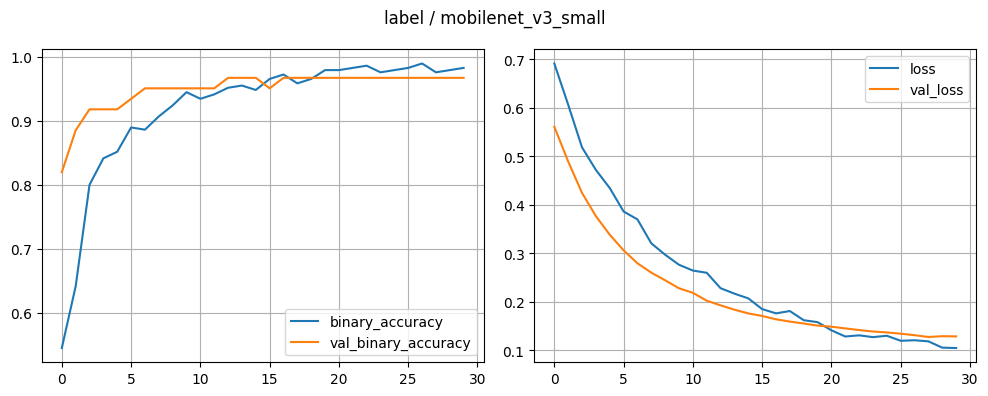

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 83s 6s/step - binary_accuracy: 0.5931 - loss: 0.6463 - val_binary_accuracy: 0.8852 - val_loss: 0.5408
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.8069 - loss: 0.5470 - val_binary_accuracy: 0.9836 - val_loss: 0.4507
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.8793 - loss: 0.4658 - val_binary_accuracy: 1.0000 - val_loss: 0.3797
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.9414 - loss: 0.3848 - val_binary_accuracy: 0.9672 - val_loss: 0.3228
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - binary_accuracy: 0.9345 - loss: 0.3411 - val_binary_accuracy: 0.9672 - val_loss: 0.2793
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.9586 - loss: 0.2962 - val_binary_accuracy: 1.0000 - val_loss: 0.2418
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.9655 - loss: 0.2543 - val_binary_accur

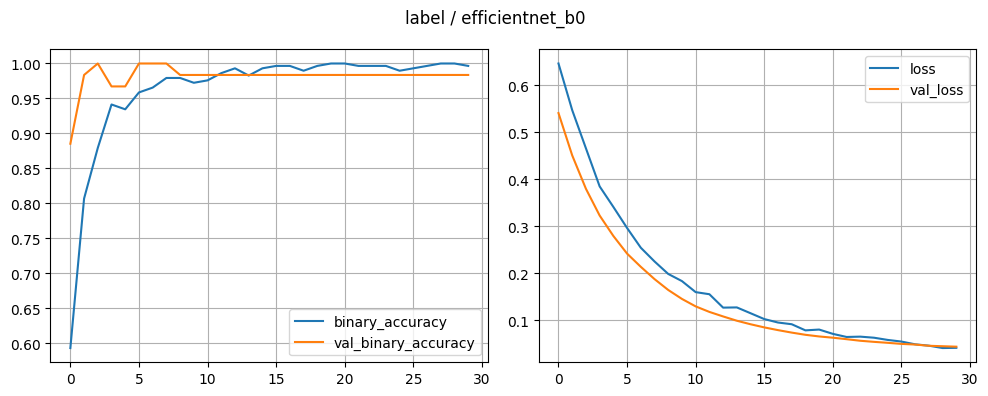

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - binary_accuracy: 0.5897 - loss: 0.6764 - val_binary_accuracy: 0.7377 - val_loss: 0.5184
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.6862 - loss: 0.5545 - val_binary_accuracy: 0.8689 - val_loss: 0.4454
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - binary_accuracy: 0.8034 - loss: 0.4566 - val_binary_accuracy: 0.9180 - val_loss: 0.3767
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.8103 - loss: 0.4405 - val_binary_accuracy: 0.9180 - val_loss: 0.3310
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.8724 - loss: 0.3626 - val_binary_accuracy: 0.9508 - val_loss: 0.2930
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - binary_accuracy: 0.8828 - loss: 0.3322 - val_binary_accuracy: 0.9344 - val_loss: 0.2606
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - binary_accuracy: 0.9138 - loss: 0.2919 - val_binary_accuracy: 0.9508 - val_loss: 0.2318
Epoch 8/30
10/10 ━━━

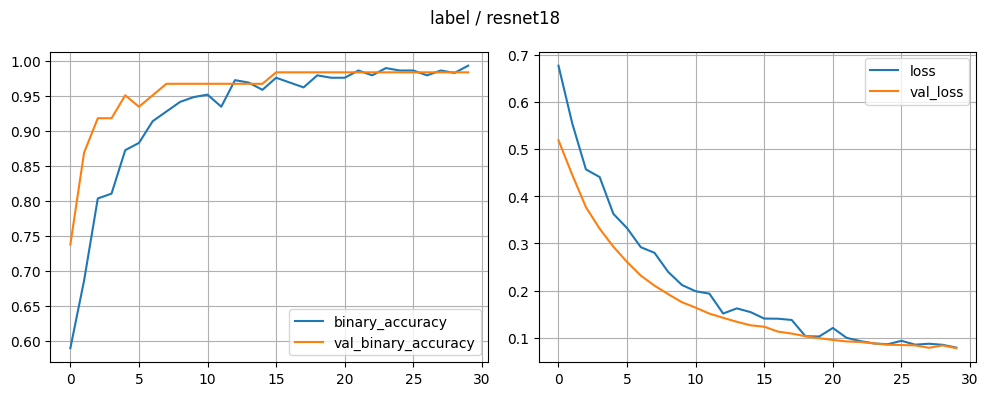

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 55s 5s/step - binary_accuracy: 0.5700 - loss: 0.6955 - val_binary_accuracy: 0.6935 - val_loss: 0.6117
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.6382 - loss: 0.6318 - val_binary_accuracy: 0.8226 - val_loss: 0.5471
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - binary_accuracy: 0.7167 - loss: 0.5712 - val_binary_accuracy: 0.7742 - val_loss: 0.5040
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - binary_accuracy: 0.7372 - loss: 0.5287 - val_binary_accuracy: 0.8065 - val_loss: 0.4696
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.7816 - loss: 0.4952 - val_binary_accuracy: 0.8387 - val_loss: 0.4345
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - binary_accuracy: 0.7782 - loss: 0.4862 - val_binary_accuracy: 0.8387 - val_loss: 0.4160
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - binary_accuracy: 0.7884 - loss: 0.4677 - val_binary_accuracy: 0.8548 - val_loss: 0.3996
Epoch 8/30
10/10 ━━━

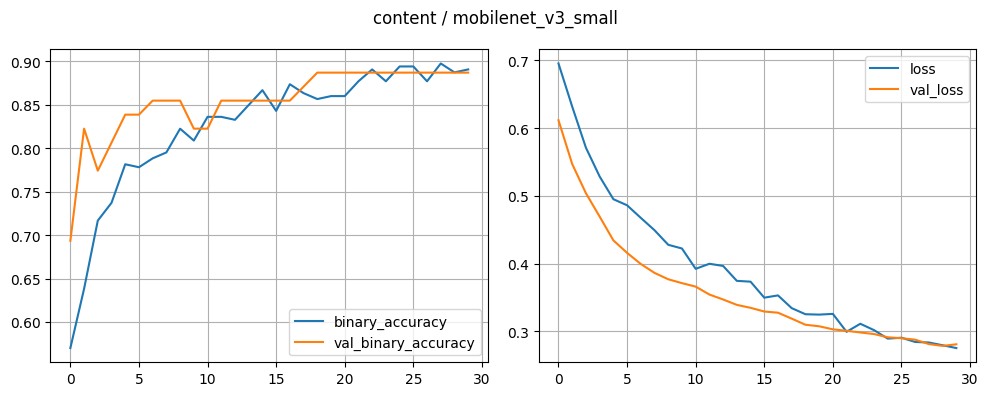

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 84s 6s/step - binary_accuracy: 0.4778 - loss: 0.7307 - val_binary_accuracy: 0.5000 - val_loss: 0.6933
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.6519 - loss: 0.6319 - val_binary_accuracy: 0.7419 - val_loss: 0.6121
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.6689 - loss: 0.5990 - val_binary_accuracy: 0.8065 - val_loss: 0.5551
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - binary_accuracy: 0.7304 - loss: 0.5465 - val_binary_accuracy: 0.7903 - val_loss: 0.5185
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.7679 - loss: 0.5004 - val_binary_accuracy: 0.7903 - val_loss: 0.4941
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - binary_accuracy: 0.8020 - loss: 0.4710 - val_binary_accuracy: 0.8226 - val_loss: 0.4722
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.8191 - loss: 0.4516 - val_binary_accuracy: 0.8548 - val_loss: 0.4485
Epoch 8/30
10/10 ━━━

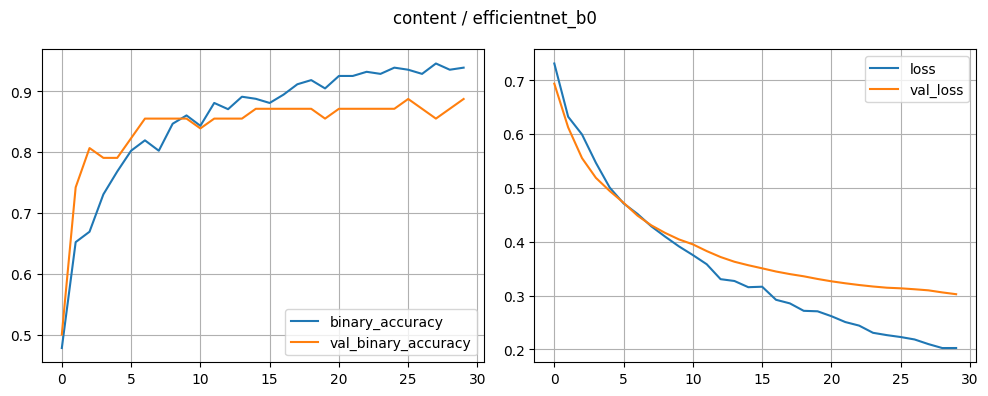

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - binary_accuracy: 0.5768 - loss: 0.7476 - val_binary_accuracy: 0.8065 - val_loss: 0.5288
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - binary_accuracy: 0.6553 - loss: 0.6704 - val_binary_accuracy: 0.7903 - val_loss: 0.4961
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - binary_accuracy: 0.6860 - loss: 0.5994 - val_binary_accuracy: 0.7903 - val_loss: 0.4647
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - binary_accuracy: 0.7440 - loss: 0.5240 - val_binary_accuracy: 0.8226 - val_loss: 0.4529
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - binary_accuracy: 0.7474 - loss: 0.5393 - val_binary_accuracy: 0.8387 - val_loss: 0.4360
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - binary_accuracy: 0.7304 - loss: 0.5483 - val_binary_accuracy: 0.8387 - val_loss: 0.4249
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - binary_accuracy: 0.7611 - loss: 0.4942 - val_binary_accuracy: 0.8548 - val_loss: 0.4175
Epoch 8/30
10/10 ━━━

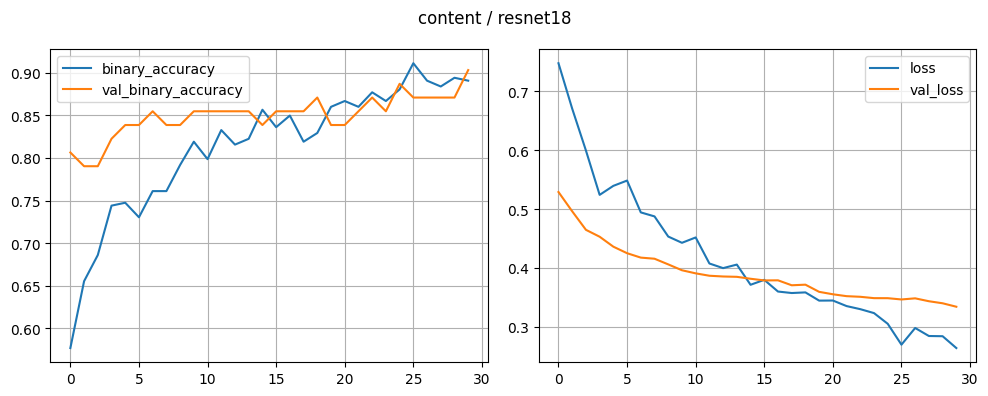

label 검증 선택: efficientnet_b0


,task,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,average_precision,specificity,false_negative_rate,tn,fp,fn,tp
0,label,mobilenet_v3_small,0.983607,0.983333,0.96875,1.000000,0.984127,0.983589,0.997849,0.997951,0.966667,0.000000,29,1,0,31
1,label,efficientnet_b0,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,30,0,0,31
2,label,resnet18,0.967213,0.967742,1.00000,0.935484,0.966667,0.967204,0.995699,0.996313,1.000000,0.064516,30,0,2,29


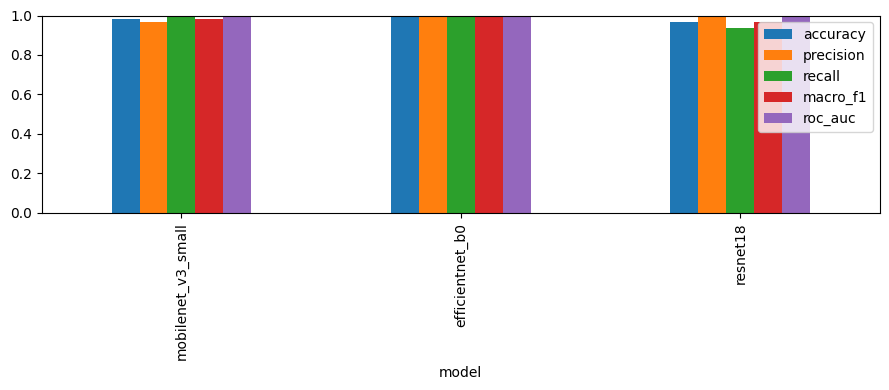

content 검증 선택: resnet18


,task,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,average_precision,specificity,false_negative_rate,tn,fp,fn,tp
3,content,mobilenet_v3_small,0.918033,0.918831,0.937500,0.909091,0.923077,0.917679,0.935065,0.956339,0.928571,0.090909,26,2,3,30
4,content,efficientnet_b0,0.885246,0.883117,0.882353,0.909091,0.895522,0.884125,0.945887,0.959725,0.857143,0.090909,24,4,3,30
5,content,resnet18,0.885246,0.885823,0.906250,0.878788,0.892308,0.884750,0.926407,0.941136,0.892857,0.121212,25,3,4,29


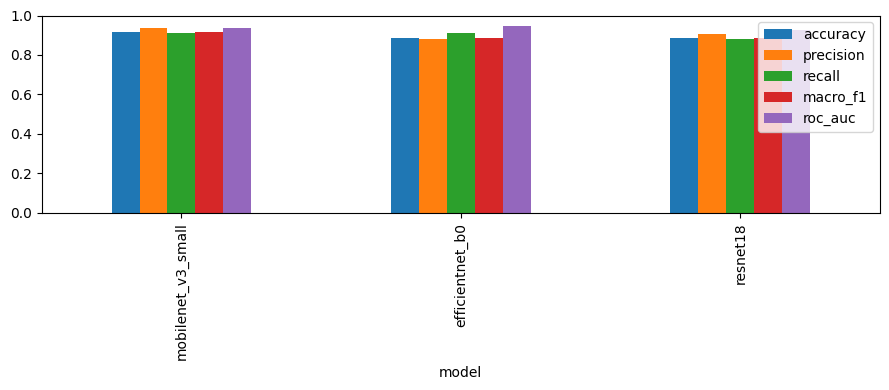

In [ ]:
validation_rows=[];test_rows=[];selected={};artifact_paths={}
for task in TASKS:
    parts=datasets[task]
    for name in MODEL_NAMES:
        tf.keras.backend.clear_session();seed_all(SEED)
        folder=RUN_DIR/task/name;folder.mkdir(parents=True)
        basename=stem(task,name);model=build_model(name)
        callbacks=[tf.keras.callbacks.ModelCheckpoint(str(folder/(basename+'.keras')),monitor='val_loss',save_best_only=True),
            tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=PATIENCE,restore_best_weights=True),
            tf.keras.callbacks.CSVLogger(str(folder/'history.csv'))]
        history=model.fit(BottleSequence(parts['train'],True),validation_data=BottleSequence(parts['val']),epochs=EPOCHS,callbacks=callbacks)
        model=tf.keras.models.load_model(folder/(basename+'.keras'),compile=False)
        m=evaluate_save(folder,'val',parts['val'],predict_probs(model,parts['val']))
        validation_rows.append({'task':task,'model':name,**m})
        meta={'task':task,'architecture':name,'input_name':'images','input_shape':[1,IMAGE_SIZE,IMAGE_SIZE,3],
            'image_size':IMAGE_SIZE,'layout':'NHWC','dtype':'float32','range':[0,255],
            'preprocessing':'EXIF transpose, RGB, PIL bilinear resize; normalization inside model',
            'output':'positive_probability','positive_meaning':'label_present' if task=='label' else 'content_present','threshold':THRESHOLD}
        save_json(folder/(basename+'.json'),meta)
        artifact_paths[(task,name)]=folder/basename
        fig,axes=plt.subplots(1,2,figsize=(10,4))
        for key in ['binary_accuracy','val_binary_accuracy']:axes[0].plot(history.history[key],label=key)
        for key in ['loss','val_loss']:axes[1].plot(history.history[key],label=key)
        for ax in axes:ax.legend();ax.grid()
        fig.suptitle(task+' / '+name);fig.tight_layout();fig.savefig(folder/'learning_curves.png',dpi=140);plt.show()
        pd.DataFrame(validation_rows).to_csv(RUN_DIR/'validation_comparison.csv',index=False)
        del model;gc.collect()
    subset=pd.DataFrame(validation_rows).query('task == @task')
    selected[task]=subset.sort_values(['macro_f1','recall','model'],ascending=[False,False,True]).iloc[0].model
save_json(RUN_DIR/'selected_models.json',{'basis':'validation macro F1, then positive recall','models':selected})
for task in TASKS:
    for name in MODEL_NAMES:
        base=artifact_paths[(task,name)];model=tf.keras.models.load_model(str(base)+'.keras',compile=False)
        test=datasets[task]['test'];m=evaluate_save(base.parent,'test',test,predict_probs(model,test))
        test_rows.append({'task':task,'model':name,**m})
test_table=pd.DataFrame(test_rows);test_table.to_csv(RUN_DIR/'test_comparison.csv',index=False)
for task in TASKS:
    print(task,'검증 선택:',selected[task]);display(test_table[test_table.task==task])
    fig,ax=plt.subplots(figsize=(9,4))
    test_table[test_table.task==task].set_index('model')[['accuracy','precision','recall','macro_f1','roc_auc']].plot.bar(ax=ax,ylim=(0,1))
    fig.tight_layout();fig.savefig(RUN_DIR/f'{task}_test_comparison.png',dpi=150);plt.show()

## 4. 이름을 지정한 ONNX 저장


In [ ]:
from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2
)

def export_onnx(model):
    spec = [
        tf.TensorSpec(
            [1, IMAGE_SIZE, IMAGE_SIZE, 3],
            tf.float32,
            name="images"
        )
    ]

    @tf.function(input_signature=spec)
    def serving(images):
        return tf.identity(
            model(images, training=False),
            name="probability"
        )

    concrete = serving.get_concrete_function()

    # 정규화 계층이 캡처한 상수 보존
    captured = {}
    for external, internal in concrete.graph.captures:
        if external.dtype != tf.resource:
            captured[internal.name.split(":")[0]] = external.numpy()

    # 학습 가중치를 상수로 고정
    frozen = convert_variables_to_constants_v2(
        concrete,
        lower_control_flow=False
    )
    graph = frozen.graph.as_graph_def(add_shapes=True)

    # 캡처된 평균·분산 등이 추가 입력으로 남으면 상수로 변환
    for node in graph.node:
        if (
            node.op in ("Placeholder", "PlaceholderWithDefault")
            and node.name in captured
        ):
            tensor = tf.make_tensor_proto(captured[node.name])
            node.op = "Const"
            del node.input[:]
            node.attr.clear()
            node.attr["dtype"].type = tensor.dtype
            node.attr["value"].tensor.CopyFrom(tensor)

    inputs = [
        node.name
        for node in graph.node
        if node.op in ("Placeholder", "PlaceholderWithDefault")
    ]

    if inputs != ["images"]:
        raise RuntimeError(
            f"상수 변환 후에도 예상하지 못한 입력이 남았습니다: {inputs}"
        )

    proto, _ = tf2onnx.convert.from_graph_def(
        graph,
        input_names=["images:0"],
        output_names=[tensor.name for tensor in frozen.outputs],
        opset=18
    )

    # 기존 사진 테스트 셀과 입력 이름 통일
    for node in proto.graph.node:
        for i, value in enumerate(node.input):
            if value == "images:0":
                node.input[i] = "images"

    for tensor in proto.graph.input:
        if tensor.name == "images:0":
            tensor.name = "images"

    onnx.checker.check_model(proto)
    return proto


def ort_session(path):
    return ort.InferenceSession(
        str(path),
        providers=["CPUExecutionProvider"]
    )


onnx_rows = []

for task in TASKS:
    for name in MODEL_NAMES:
        print(f"\n변환 중: {task} / {name}")

        base = artifact_paths[(task, name)]
        model = tf.keras.models.load_model(
            str(base) + ".keras",
            compile=False
        )

        proto = export_onnx(model)

        session = ort.InferenceSession(
            proto.SerializeToString(),
            providers=["CPUExecutionProvider"]
        )

        input_names = [item.name for item in session.get_inputs()]
        if input_names != ["images"]:
            raise RuntimeError(f"ONNX 입력 확인 실패: {input_names}")

        # 실제 검증 이미지에서 Keras / ONNX 예측 비교
        errors = []

        for path in datasets[task]["val"].full_path.iloc[:8]:
            x = load_array(path)[None]

            expected = model(x, training=False).numpy()
            actual = session.run(None, {"images": x})[0]

            np.testing.assert_allclose(
                actual,
                expected,
                rtol=1e-3,
                atol=1e-4
            )
            errors.append(float(np.max(np.abs(actual - expected))))

        # 검증에 통과한 모델만 기존 이름으로 저장
        onnx_path = str(base) + ".onnx"
        onnx.save_model(proto, onnx_path)

        save_json(
            base.parent / "onnx_check.json",
            {
                "passed": True,
                "inputs": input_names,
                "max_abs_error": max(errors)
            }
        )

        # ONNX 테스트 성능 저장
        test = datasets[task]["test"]
        q = np.array([
            session.run(
                None,
                {"images": load_array(path)[None]}
            )[0].item()
            for path in test.full_path
        ])

        onnx_rows.append({
            "task": task,
            "model": name,
            **evaluate_save(base.parent, "test_onnx", test, q)
        })

        # 모델 하나가 끝날 때마다 비교 결과 저장
        pd.DataFrame(onnx_rows).to_csv(
            RUN_DIR / "onnx_test_comparison.csv",
            index=False
        )

        print("저장 완료:", onnx_path)

display(pd.DataFrame(onnx_rows))


변환 중: label / mobilenet_v3_small


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


저장 완료: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/mobilenet_v3_small/pet_inspection_v1_label_mobilenet_v3_small.onnx

변환 중: label / efficientnet_b0
저장 완료: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/efficientnet_b0/pet_inspection_v1_label_efficientnet_b0.onnx

변환 중: label / resnet18
저장 완료: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/resnet18/pet_inspection_v1_label_resnet18.onnx

변환 중: content / mobilenet_v3_small
저장 완료: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/content/mobilenet_v3_small/pet_inspection_v1_content_mobilenet_v3_small.onnx

변환 중: content / efficientnet_b0
저장 완료: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/content/efficientnet_b0/pet_inspection_v1_content_efficientnet_b0.onnx

변환 중: content / resnet18
저장 완료: /content/dri

,task,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,average_precision,specificity,false_negative_rate,tn,fp,fn,tp
0,label,mobilenet_v3_small,0.983607,0.983333,0.968750,1.000000,0.984127,0.983589,0.997849,0.997951,0.966667,0.000000,29,1,0,31
1,label,efficientnet_b0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,30,0,0,31
2,label,resnet18,0.967213,0.967742,1.000000,0.935484,0.966667,0.967204,0.995699,0.996313,1.000000,0.064516,30,0,2,29
3,content,mobilenet_v3_small,0.918033,0.918831,0.937500,0.909091,0.923077,0.917679,0.935065,0.956339,0.928571,0.090909,26,2,3,30
4,content,efficientnet_b0,0.885246,0.883117,0.882353,0.909091,0.895522,0.884125,0.945887,0.959725,0.857143,0.090909,24,4,3,30
5,content,resnet18,0.885246,0.885823,0.906250,0.878788,0.892308,0.884750,0.926407,0.941136,0.892857,0.121212,25,3,4,29


## 5. 사진 업로드와 순차 테스트


Saving pet_20260910_152142_588_0547.jpg to pet_20260910_152142_588_0547.jpg
사진: 0_pet_20260910_152142_588_0547.jpg


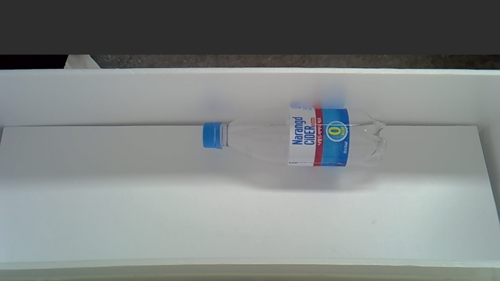

,모델,라벨 예측,라벨 있음 확률,내용물 예측,내용물 있음 확률,선별 결과,판정 이유
0,mobilenet_v3_small,있음,92.3%,없음,48.9%,불통과,라벨 제거 필요
1,efficientnet_b0,있음,66.2%,없음,28.0%,불통과,라벨 제거 필요
2,resnet18,있음,68.8%,없음,24.8%,불통과,라벨 제거 필요


,image,model,label_present,content_present,label_probability,content_probability,label_threshold,content_threshold,sorting_pass,decision
0,/content/drive/MyDrive/ai/final/model_multilab...,mobilenet_v3_small,True,False,0.923397,0.488765,0.5,0.5,False,라벨 제거 필요
1,/content/drive/MyDrive/ai/final/model_multilab...,efficientnet_b0,True,False,0.662488,0.280186,0.5,0.5,False,라벨 제거 필요
2,/content/drive/MyDrive/ai/final/model_multilab...,resnet18,True,False,0.687696,0.247557,0.5,0.5,False,라벨 제거 필요


In [ ]:
IMAGE_PATHS=[]  # 로컬 예: ['/path/to/bottle.jpg']
UPLOAD_IN_COLAB=True
if UPLOAD_IN_COLAB:
    try:from google.colab import files
    except ImportError:print('로컬에서는 IMAGE_PATHS를 지정하세요.')
    else:
        uploaded=files.upload();upload_dir=RUN_DIR/'uploaded_tests';upload_dir.mkdir(exist_ok=True)
        for index,(filename,data) in enumerate(uploaded.items()):
            path=upload_dir/(str(index)+'_'+Path(filename).name);path.write_bytes(data);IMAGE_PATHS.append(str(path))
def combine_decisions(label_present,content_present):
    if label_present and content_present:return '라벨 제거 및 내용물 비우기 필요'
    if label_present:return '라벨 제거 필요'
    if content_present:return '내용물 비우기 필요'
    return '선별 기준 통과'
if IMAGE_PATHS:
    sessions={};metas={}
    for name in MODEL_NAMES:
        for task in ['label','content']:
            base=artifact_paths[(task,name)]
            sessions[(task,name)]=ort_session(str(base)+'.onnx')
            metas[(task,name)]=json.loads(Path(str(base)+'.json').read_text(encoding='utf-8'))
    results=[]
    for path in IMAGE_PATHS:
        x=load_array(path)[None];image_rows=[]
        for name in MODEL_NAMES:
            pred={};prob={}
            for task in ['label','content']:
                prob[task]=float(sessions[(task,name)].run(None,{'images':x})[0].item())
                pred[task]=prob[task]>=metas[(task,name)]['threshold']
            row={'image':str(path),'model':name,
                'label_present':pred['label'],'content_present':pred['content'],
                'label_probability':prob['label'],'content_probability':prob['content'],
                'label_threshold':metas[('label',name)]['threshold'],
                'content_threshold':metas[('content',name)]['threshold'],
                'sorting_pass':not(pred['label'] or pred['content']),
                'decision':combine_decisions(pred['label'],pred['content'])}
            results.append(row);image_rows.append(row)
        print('사진:',Path(path).name)
        with Image.open(path) as im:
            preview=ImageOps.exif_transpose(im).convert('RGB');preview.thumbnail((500,500));display(preview)
        view=pd.DataFrame([{'모델':r['model'],'라벨 예측':'있음' if r['label_present'] else '없음',
            '라벨 있음 확률':f"{r['label_probability']:.1%}",'내용물 예측':'있음' if r['content_present'] else '없음',
            '내용물 있음 확률':f"{r['content_probability']:.1%}",'선별 결과':'통과' if r['sorting_pass'] else '불통과',
            '판정 이유':r['decision']} for r in image_rows])
        display(view)
        if len({(r['label_present'],r['content_present']) for r in image_rows})>1:
            print('모델 간 예측이 다릅니다. 사진과 정답을 확인하세요.')
    pd.DataFrame(results).to_csv(RUN_DIR/'uploaded_predictions.csv',index=False,encoding='utf-8-sig')
    save_json(RUN_DIR/'uploaded_predictions.json',results);display(pd.DataFrame(results))

## 6. 모델·평가 결과 다운로드
ONNX 6개와 대응 JSON을 개별 다운로드하거나 전체 ZIP을 받을 수 있습니다.


In [ ]:
import zipfile
zip_path=RUN_DIR.parent/(RUN_DIR.name+'.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in RUN_DIR.rglob('*'):
        if path.is_file() and 'uploaded_tests' not in path.relative_to(RUN_DIR).parts:z.write(path,path.relative_to(RUN_DIR))
display(FileLink(str(zip_path)))
for base in artifact_paths.values():
    display(FileLink(str(base)+'.onnx'));display(FileLink(str(base)+'.json'))
DOWNLOAD_ZIP_IN_COLAB=True
if DOWNLOAD_ZIP_IN_COLAB:
    try:from google.colab import files
    except ImportError:print('위 링크에서 다운로드하세요.')
    else:files.download(str(zip_path))
print("Drive 결과 폴더:",RUN_DIR)
print("Drive 전체 결과 ZIP:",zip_path)


/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726.zip

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/mobilenet_v3_small/pet_inspection_v1_label_mobilenet_v3_small.onnx

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/mobilenet_v3_small/pet_inspection_v1_label_mobilenet_v3_small.json

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/efficientnet_b0/pet_inspection_v1_label_efficientnet_b0.onnx

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/label/efficientnet_b0/pet_inspection_v1_label_efficientnet_b0.json

...

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/content/resnet18/pet_inspection_v1_content_resnet18.onnx

/content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726/content/resnet18/pet_inspection_v1_content_resnet18.json

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive 결과 폴더: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726
Drive 전체 결과 ZIP: /content/drive/MyDrive/ai/final/model_multilabel/Results/pet_inspection_v1_20260913_063726.zip
